# Shape Transformation using Variational Implicit Functions Notebook Implementation

Notebook implementation by Andy Thai

Sample implementation: https://github.com/fiji/VIB/blob/master/src/main/java/Implicit_Interpolate_Binary.java

Set up our interpolation function f(x):

$
f(x) = \sum_{j=1}^k d_j \phi(x - c_j) + P(x) 
$

<br>

We want to solve for $d_j$ and the coefficients of $P(x)$. To solve for $d_j$, we can substitute the right side of the above equation for $f(\textbf{c}_i)$ for the constraints $h_i = f(\textbf{c}_i)$ to get the below equation, where $h_i$ is the height value:

$
h_i = \sum_{j=1}^k d_j \phi(c_i - c_j) + P(c_i) 
$

<br>
We can represent this equation as the matrix in the 3D interpolation case, where $h_i$ is corresponding x or y coordinate, depending on whether you are solving for $f'_{x}$ or $f'_{y}$:

$
\begin{bmatrix}
\phi_{11} & \phi_{12} & \ldots & \phi_{1k} & 1 & c_1^x & c_1^y & c_1^z \\
\phi_{21} & \phi_{22} & \ldots & \phi_{2k} & 1 & c_2^x & c_2^y & c_2^z \\
\vdots & \vdots & \ldots & \vdots & \vdots & \vdots & \vdots & \vdots \\
\phi_{k1} & \phi_{k2} & \ldots & \phi_{kk} & 1 & c_k^x & c_k^y & c_k^z \\
1 & 1 & \ldots & 1 & 0 & 0 & 0 & 0 \\
c_1^x & c_2^x & \ldots & c_k^x & 0 & 0 & 0 & 0 \\
c_1^y & c_2^y & \ldots & c_k^y & 0 & 0 & 0 & 0 \\
c_1^z & c_2^z & \ldots & c_k^z & 0 & 0 & 0 & 0 \\
\end{bmatrix}
\begin{bmatrix}
d_1 \\ 
d_2 \\
\vdots \\
d_k \\
p_0 \\
p_1 \\
p_2 \\
p_3 \\
\end{bmatrix}
=
\begin{bmatrix}
h_1 \\ 
h_2 \\
\vdots \\
h_k \\
0 \\
0 \\
0 \\
0 \\
\end{bmatrix}
$

<br>
Let $\phi_{ij} = \phi(\textbf{c}_i - \textbf{c}_j)$

$p_0, p_1, p_2, p_3$ can also be written as $p_0, p_x, p_y, p_z$ respectively.



In [1]:
%load_ext autoreload
%autoreload 2

## Import libraries

In [2]:
# Standard library test
import time
from pprint import pprint
import glob

# Third-party libraries
import numpy as np
import matplotlib.pyplot as plt
import scipy
import skimage.morphology
from skimage.morphology import disk
from skimage.filters import median

#from jupyterthemes import jtplot; jtplot.style()

# My libraries
from modules.implicit import ImplicitFunction
import modules.utils as utils

## Setup sample 3D example

In [3]:
npy_file = "data/1006_label.npy"
IDX1 = 54
IDX2 = 60
volume = np.load(npy_file)

Mall1 = volume[:, :, IDX1].copy()
Mall2 = volume[:, :, IDX2].copy()

where_1 = np.where(volume != 0)
volume[where_1] = 1

#np.save("data/npy/both.npy", volume)
# Setup 3D volume
M1 = volume[:, :, IDX1]  # 64
M2 = volume[:, :, IDX2]  # 68

print(M1.shape)

np.unique(Mall2)

(256, 256)


array([  0., 205., 500., 600., 850.])

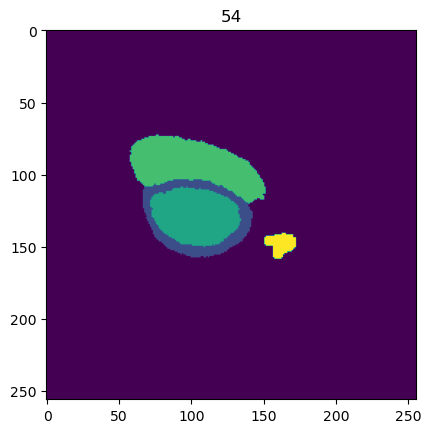

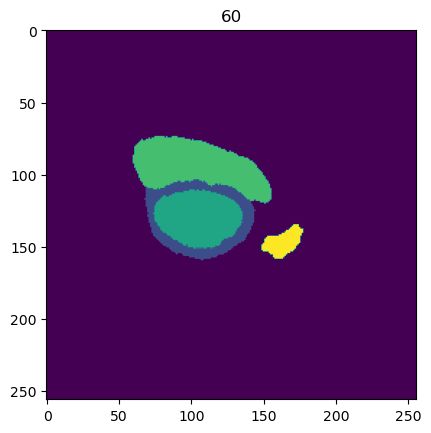

In [4]:
plt.title(str(IDX1))
plt.imshow(Mall1); plt.show()

plt.title(str(IDX2))
plt.imshow(Mall2); plt.show()

### Test implementation for 3D interpolation input

## 1-31-24 Test

Combined labels

M = [M1, M2]
M = np.array(M)
print(M.shape)

plt.imshow(M1)
plt.title('0')
plt.axis(False)
plt.show()

# Create implicit surface
start = time.time()
imp = ImplicitFunction(M, tmax=1)
end = time.time() - start
print(f"Elapsed time: {end}")

# Interpolate image at some parametrization t
start = time.time()
img = imp.interpolate(0)
plt.title("Interp 0"); plt.imshow(img); plt.show()
end = time.time() - start
print(f"Elapsed time: {end}")

print("0 with boundary constraints")
imp.data.show(0, img, [0])
print("0 with normal constraints")
imp.data.show(0, img, [1])
print("0 with outside constraints")
imp.data.show(0, img, [-1])

img = imp.interpolate(0.25)
plt.title("0.25"); plt.imshow(img); plt.axis(False); plt.show()

img = imp.interpolate(0.5)
plt.title("0.5"); plt.imshow(img); plt.axis(False); plt.show()

plt.imshow(M2)
plt.title('1')
plt.axis(False)
plt.show()

All labels

Label 205.0
DEBUG: Creating constraints.
before
[(array([ 88, 104,   0]), 0), (array([ 87, 105,   0]), 0), (array([ 86, 105,   0]), 0), (array([ 85, 105,   0]), 0), (array([ 84, 105,   0]), 0), (array([ 83, 106,   0]), 0), (array([ 82, 106,   0]), 0), (array([ 81, 107,   0]), 0), (array([ 80, 107,   0]), 0), (array([ 79, 107,   0]), 0), (array([ 78, 108,   0]), 0), (array([ 77, 108,   0]), 0), (array([ 76, 108,   0]), 0), (array([ 75, 107,   0]), 0), (array([ 74, 108,   0]), 0), (array([ 73, 109,   0]), 0), (array([ 72, 109,   0]), 0), (array([ 71, 109,   0]), 0), (array([ 70, 109,   0]), 0), (array([ 69, 109,   0]), 0), (array([ 68, 109,   0]), 0), (array([ 68, 110,   0]), 0), (array([ 67, 111,   0]), 0), (array([ 67, 112,   0]), 0), (array([ 67, 113,   0]), 0), (array([ 67, 114,   0]), 0), (array([ 67, 115,   0]), 0), (array([ 67, 116,   0]), 0), (array([ 67, 117,   0]), 0), (array([ 67, 118,   0]), 0), (array([ 67, 119,   0]), 0), (array([ 67, 120,   0]), 0), (array([ 67, 121,   0])

Creating matrix:   0%|          | 0/1227 [00:00<?, ?it/s]

DEBUG: Finished constructing matrix
Elapsed time: 0.30535054206848145

DEBUG: Solving matrix.
DEBUG: Finished solving matrix.
Elapsed time: 0.012939453125
Elapsed time: 0.5049479007720947


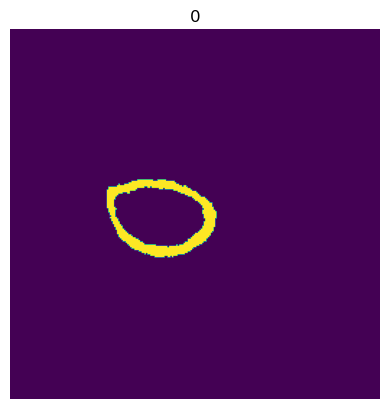

Interpolating image:   0%|          | 0/256 [00:00<?, ?it/s]

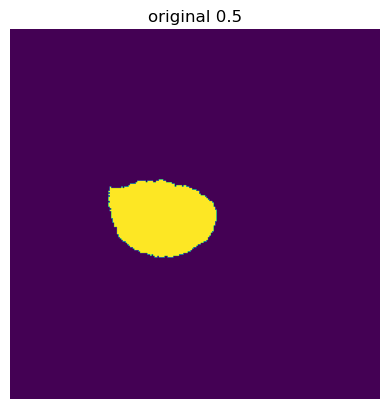

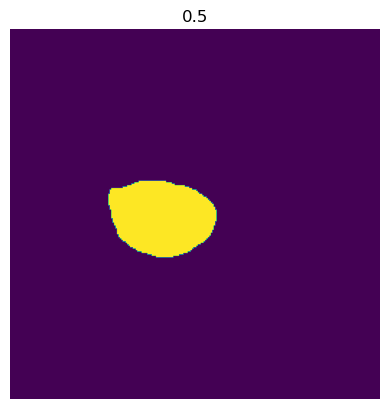

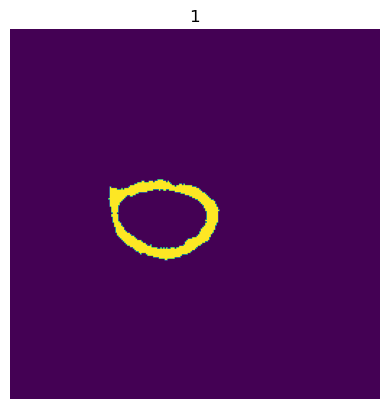

Label 500.0
DEBUG: Creating constraints.
before
[(array([ 93, 109,   0]), 0), (array([ 92, 110,   0]), 0), (array([ 91, 110,   0]), 0), (array([ 90, 110,   0]), 0), (array([ 89, 110,   0]), 0), (array([ 88, 110,   0]), 0), (array([ 87, 111,   0]), 0), (array([ 86, 112,   0]), 0), (array([ 85, 112,   0]), 0), (array([ 84, 112,   0]), 0), (array([ 83, 112,   0]), 0), (array([ 83, 113,   0]), 0), (array([ 82, 114,   0]), 0), (array([ 81, 114,   0]), 0), (array([ 80, 113,   0]), 0), (array([ 79, 113,   0]), 0), (array([ 78, 113,   0]), 0), (array([ 77, 114,   0]), 0), (array([ 76, 114,   0]), 0), (array([ 75, 114,   0]), 0), (array([ 74, 115,   0]), 0), (array([ 73, 116,   0]), 0), (array([ 73, 117,   0]), 0), (array([ 72, 118,   0]), 0), (array([ 72, 119,   0]), 0), (array([ 72, 120,   0]), 0), (array([ 72, 121,   0]), 0), (array([ 72, 122,   0]), 0), (array([ 73, 123,   0]), 0), (array([ 74, 124,   0]), 0), (array([ 73, 125,   0]), 0), (array([ 73, 126,   0]), 0), (array([ 73, 127,   0])

Creating matrix:   0%|          | 0/966 [00:00<?, ?it/s]

DEBUG: Finished constructing matrix
Elapsed time: 0.23507428169250488

DEBUG: Solving matrix.
DEBUG: Finished solving matrix.
Elapsed time: 0.008071660995483398
Elapsed time: 0.41170382499694824


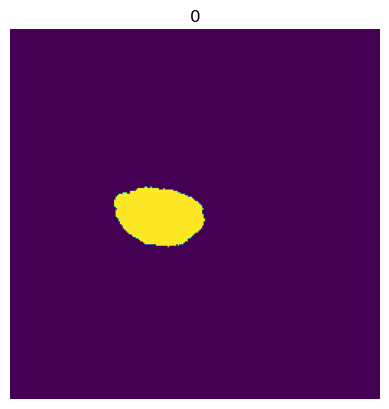

Interpolating image:   0%|          | 0/256 [00:00<?, ?it/s]

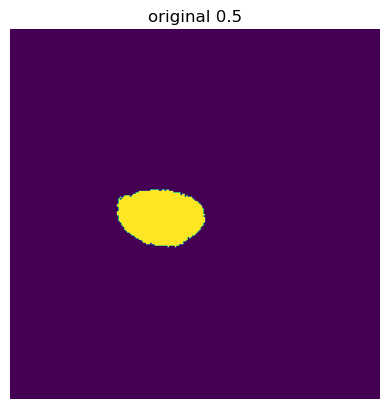

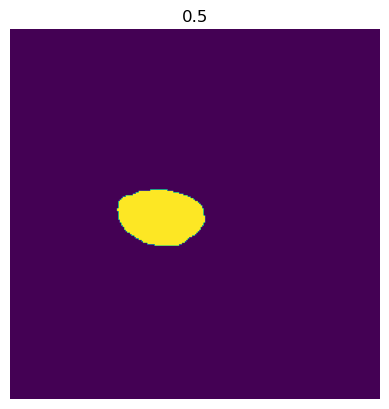

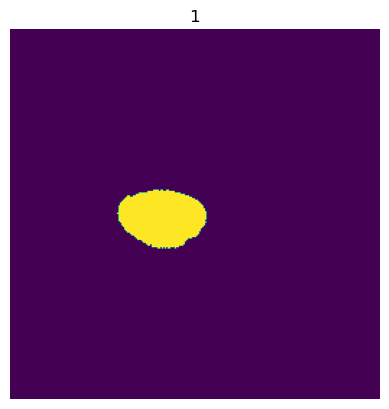

Label 600.0
DEBUG: Creating constraints.
before
[(array([76, 73,  0]), 0), (array([75, 74,  0]), 0), (array([74, 74,  0]), 0), (array([73, 74,  0]), 0), (array([72, 74,  0]), 0), (array([71, 74,  0]), 0), (array([70, 75,  0]), 0), (array([69, 75,  0]), 0), (array([68, 75,  0]), 0), (array([67, 76,  0]), 0), (array([66, 76,  0]), 0), (array([65, 77,  0]), 0), (array([64, 77,  0]), 0), (array([63, 77,  0]), 0), (array([62, 78,  0]), 0), (array([61, 79,  0]), 0), (array([60, 80,  0]), 0), (array([59, 81,  0]), 0), (array([59, 82,  0]), 0), (array([59, 83,  0]), 0), (array([58, 84,  0]), 0), (array([59, 85,  0]), 0), (array([59, 86,  0]), 0), (array([58, 87,  0]), 0), (array([58, 88,  0]), 0), (array([58, 89,  0]), 0), (array([58, 90,  0]), 0), (array([58, 91,  0]), 0), (array([59, 92,  0]), 0), (array([59, 93,  0]), 0), (array([59, 94,  0]), 0), (array([60, 95,  0]), 0), (array([60, 96,  0]), 0), (array([61, 97,  0]), 0), (array([61, 98,  0]), 0), (array([61, 99,  0]), 0), (array([ 62, 10


after
[(array([76, 73,  0]), 0), (array([75, 74,  0]), 0), (array([74, 74,  0]), 0), (array([73, 74,  0]), 0), (array([72, 74,  0]), 0), (array([71, 74,  0]), 0), (array([70, 75,  0]), 0), (array([69, 75,  0]), 0), (array([68, 75,  0]), 0), (array([67, 76,  0]), 0), (array([66, 76,  0]), 0), (array([65, 77,  0]), 0), (array([64, 77,  0]), 0), (array([63, 77,  0]), 0), (array([62, 78,  0]), 0), (array([61, 79,  0]), 0), (array([60, 80,  0]), 0), (array([59, 81,  0]), 0), (array([59, 82,  0]), 0), (array([59, 83,  0]), 0), (array([58, 84,  0]), 0), (array([59, 85,  0]), 0), (array([59, 86,  0]), 0), (array([58, 87,  0]), 0), (array([58, 88,  0]), 0), (array([58, 89,  0]), 0), (array([58, 90,  0]), 0), (array([58, 91,  0]), 0), (array([59, 92,  0]), 0), (array([59, 93,  0]), 0), (array([59, 94,  0]), 0), (array([60, 95,  0]), 0), (array([60, 96,  0]), 0), (array([61, 97,  0]), 0), (array([61, 98,  0]), 0), (array([61, 99,  0]), 0), (array([ 62, 100,   0]), 0), (array([ 62, 101,   0]), 0)

Creating matrix:   0%|          | 0/1386 [00:00<?, ?it/s]

DEBUG: Finished constructing matrix
Elapsed time: 0.511427640914917

DEBUG: Solving matrix.
DEBUG: Finished solving matrix.
Elapsed time: 0.025383949279785156
Elapsed time: 0.8764517307281494


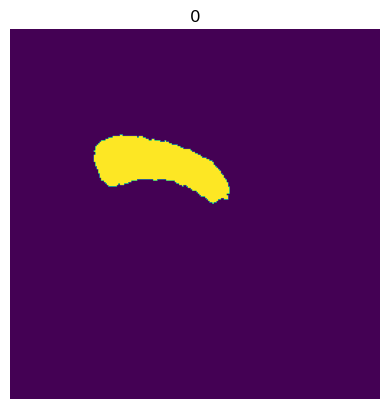

Interpolating image:   0%|          | 0/256 [00:00<?, ?it/s]

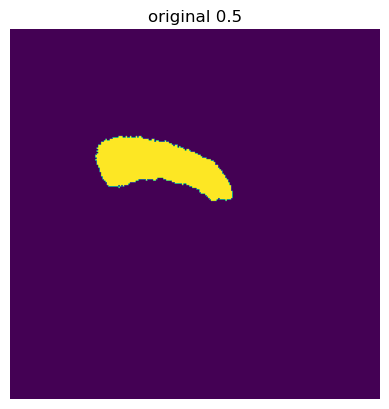

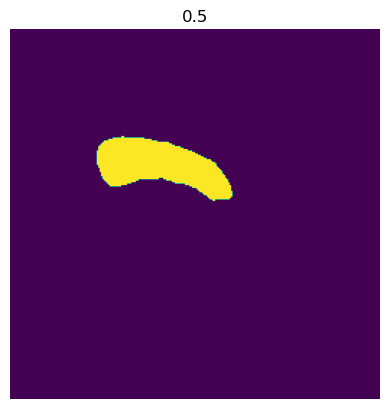

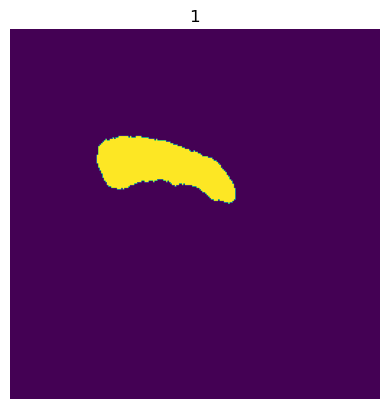

Label 850.0
DEBUG: Creating constraints.
before
[(array([163, 141,   0]), 0), (array([162, 142,   0]), 0), (array([161, 142,   0]), 0), (array([160, 142,   0]), 0), (array([159, 142,   0]), 0), (array([158, 142,   0]), 0), (array([157, 143,   0]), 0), (array([156, 143,   0]), 0), (array([155, 143,   0]), 0), (array([154, 143,   0]), 0), (array([153, 143,   0]), 0), (array([152, 143,   0]), 0), (array([151, 144,   0]), 0), (array([151, 145,   0]), 0), (array([151, 146,   0]), 0), (array([151, 147,   0]), 0), (array([151, 148,   0]), 0), (array([152, 149,   0]), 0), (array([153, 149,   0]), 0), (array([154, 149,   0]), 0), (array([155, 149,   0]), 0), (array([156, 149,   0]), 0), (array([157, 150,   0]), 0), (array([157, 151,   0]), 0), (array([157, 152,   0]), 0), (array([157, 153,   0]), 0), (array([157, 154,   0]), 0), (array([157, 155,   0]), 0), (array([157, 156,   0]), 0), (array([157, 157,   0]), 0), (array([158, 158,   0]), 0), (array([159, 158,   0]), 0), (array([160, 158,   0])

Creating matrix:   0%|          | 0/467 [00:00<?, ?it/s]

DEBUG: Finished constructing matrix
Elapsed time: 0.0731356143951416

DEBUG: Solving matrix.
DEBUG: Finished solving matrix.
Elapsed time: 0.0014357566833496094
Elapsed time: 0.1514756679534912


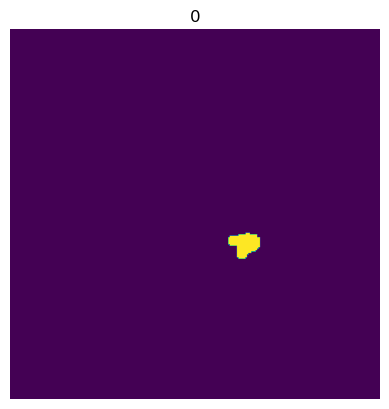

Interpolating image:   0%|          | 0/256 [00:00<?, ?it/s]

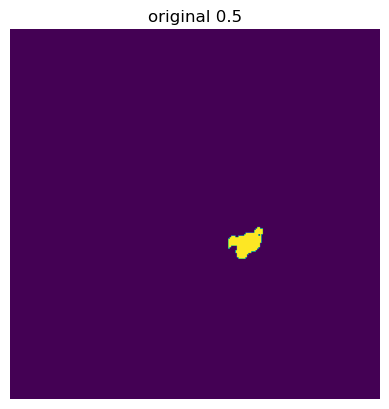

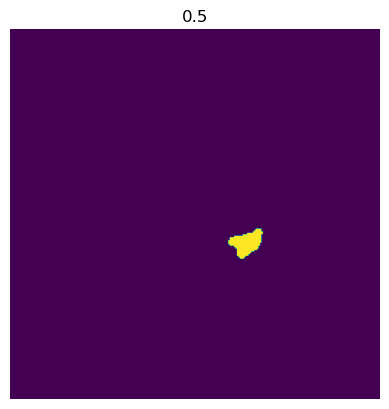

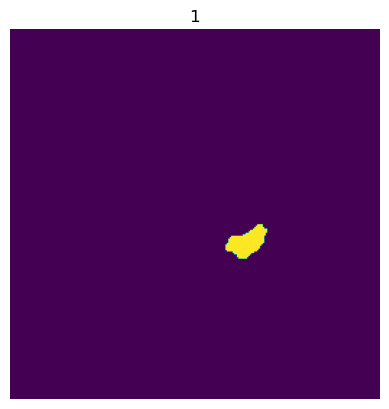

In [16]:
interp_output = {}
Mall = [Mall1, Mall2]
Mall = np.array(Mall)

for label in np.unique(Mall):
    if label != 0:
        print("Label", label)
        where_L = np.where(Mall != label)
        curr_M = Mall.copy()
        curr_M[where_L] = 0
        curr_M[curr_M == label] = 1

        # Create implicit surface
        start = time.time()
        imp = ImplicitFunction(curr_M, tmax=1)
        end = time.time() - start
        print(f"Elapsed time: {end}")

        # Interpolate image at some parametrization t
        #start = time.time()
        #img = imp.interpolate(0)
        plt.title("0"); plt.imshow(curr_M[0]); plt.axis(False); plt.show()
        
        #end = time.time() - start
        #print(f"Elapsed time: {end}")

        #print("0 with boundary constraints")
        #imp.data.show(0, img, [0])
        #print("0 with normal constraints")
        #imp.data.show(0, img, [1])
        #print("0 with outside constraints")
        #imp.data.show(0, img, [-1])

        #img = imp.interpolate(0.25)
        #plt.title("0.25"); plt.imshow(img); plt.axis(False); plt.show()

        img = imp.interpolate(0.5)
        plt.title("original 0.5"); plt.imshow(img); plt.axis(False); plt.show()
        img = skimage.morphology.remove_small_objects(img.astype(bool))
        img = skimage.morphology.remove_small_holes(img.astype(bool))
        img = median(img, disk(3))
        plt.title("0.5"); plt.imshow(img); plt.axis(False); plt.show()
        interp_output[label] = img
        
        plt.title("1"); plt.imshow(curr_M[1]); plt.axis(False); plt.show()

In [12]:
imp.data.constraints[0]

[(array([163, 141,   0]), 0),
 (array([162, 142,   0]), 0),
 (array([161, 142,   0]), 0),
 (array([160, 142,   0]), 0),
 (array([159, 142,   0]), 0),
 (array([158, 142,   0]), 0),
 (array([157, 143,   0]), 0),
 (array([156, 143,   0]), 0),
 (array([155, 143,   0]), 0),
 (array([154, 143,   0]), 0),
 (array([153, 143,   0]), 0),
 (array([152, 143,   0]), 0),
 (array([151, 144,   0]), 0),
 (array([151, 145,   0]), 0),
 (array([151, 146,   0]), 0),
 (array([151, 147,   0]), 0),
 (array([151, 148,   0]), 0),
 (array([152, 149,   0]), 0),
 (array([153, 149,   0]), 0),
 (array([154, 149,   0]), 0),
 (array([155, 149,   0]), 0),
 (array([156, 149,   0]), 0),
 (array([157, 150,   0]), 0),
 (array([157, 151,   0]), 0),
 (array([157, 152,   0]), 0),
 (array([157, 153,   0]), 0),
 (array([157, 154,   0]), 0),
 (array([157, 155,   0]), 0),
 (array([157, 156,   0]), 0),
 (array([157, 157,   0]), 0),
 (array([158, 158,   0]), 0),
 (array([159, 158,   0]), 0),
 (array([160, 158,   0]), 0),
 (array([1

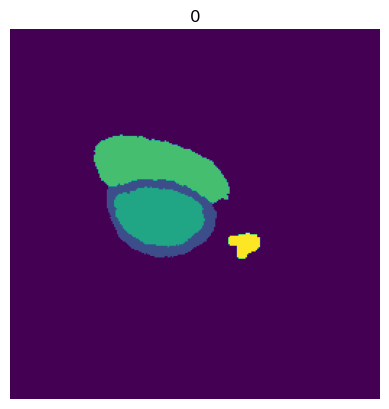

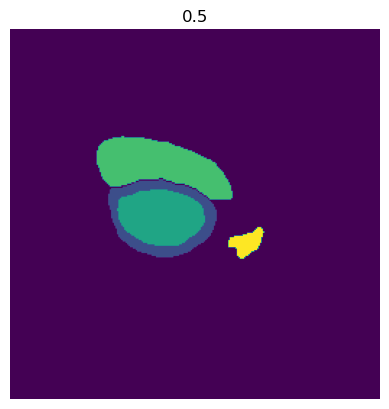

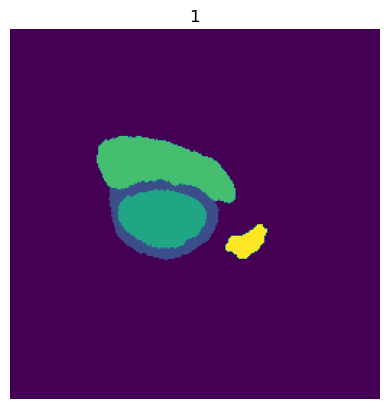

In [6]:
# Combine all labels into one image
canvas = np.zeros(Mall1.shape)
for key in interp_output.keys():
    curr_label = interp_output[key]
    where_label = np.where(curr_label != 0)
    canvas[where_label] = key
    

plt.title('0')
plt.axis(False)
plt.imshow(Mall1)
plt.show()
    
plt.title('0.5')
plt.axis(False)
plt.imshow(canvas)
plt.show()


plt.title('1')
plt.axis(False)
plt.imshow(Mall2)
plt.show()

Do it again with a tlist

In [35]:
def normalize_tlist(tlist, tmax):
    return list(np.array(tlist) / tmax)

def get_idx(idx, tmax):
    return idx / tmax


tlist = [0, 0.85]

print(normalize_tlist(tlist, 0.85))
print(get_idx(0., 0.85))

[0.0, 1.0]
0.0


t norm: 0.5833333333333334
tlist norm: [0.0, 0.16666666666666666, 0.5, 0.9, 1.0]
Label 205.0
DEBUG: Creating constraints.
(5315, 3)
DEBUG: Finished creating constraints.
Elapsed time: 2.873243570327759

DEBUG: Creating matrix.


Creating matrix:   0%|          | 0/5315 [00:00<?, ?it/s]

DEBUG: Finished constructing matrix
Elapsed time: 6.245206356048584

DEBUG: Solving matrix.
DEBUG: Finished solving matrix.
Elapsed time: 1.0340423583984375
Elapsed time: 10.429039478302002


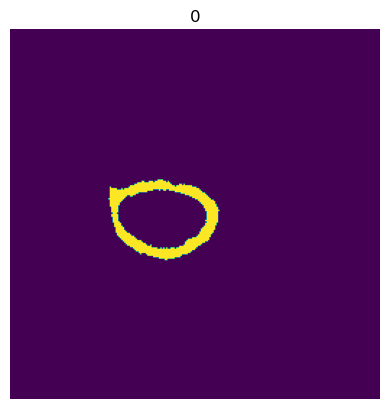

Interpolating image:   0%|          | 0/256 [00:00<?, ?it/s]

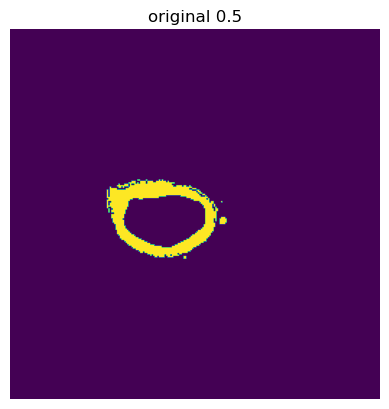

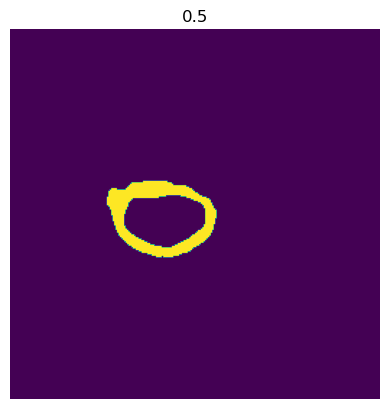

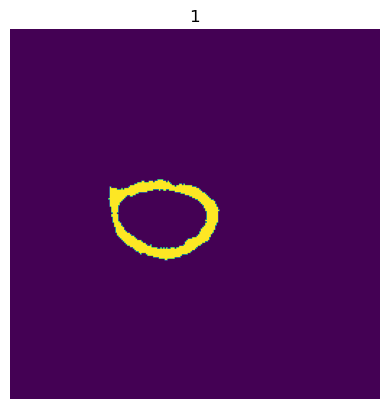

Label 500.0
DEBUG: Creating constraints.
(4637, 3)
DEBUG: Finished creating constraints.
Elapsed time: 2.8065056800842285

DEBUG: Creating matrix.


Creating matrix:   0%|          | 0/4637 [00:00<?, ?it/s]

DEBUG: Finished constructing matrix
Elapsed time: 4.676238775253296

DEBUG: Solving matrix.
DEBUG: Finished solving matrix.
Elapsed time: 0.6759815216064453
Elapsed time: 8.4120512008667


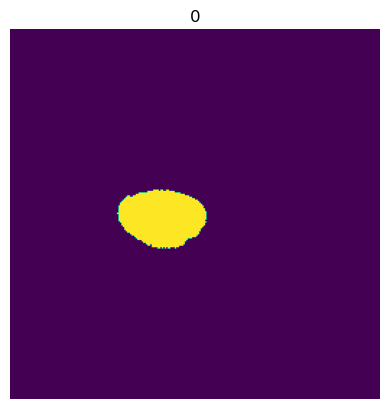

Interpolating image:   0%|          | 0/256 [00:00<?, ?it/s]

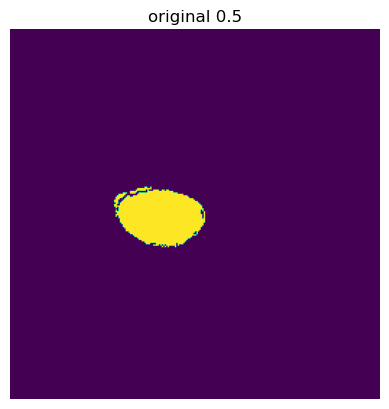

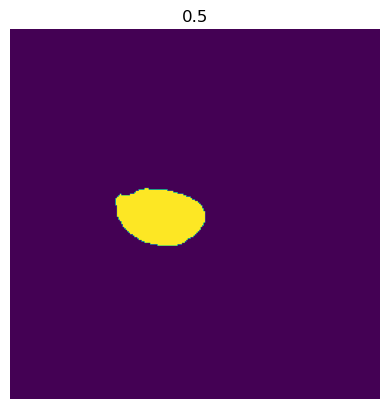

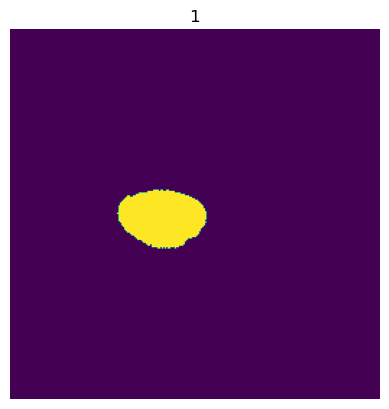

Label 600.0
DEBUG: Creating constraints.
(5723, 3)
DEBUG: Finished creating constraints.
Elapsed time: 3.7750935554504395

DEBUG: Creating matrix.


Creating matrix:   0%|          | 0/5723 [00:00<?, ?it/s]

DEBUG: Finished constructing matrix
Elapsed time: 7.133265256881714

DEBUG: Solving matrix.
DEBUG: Finished solving matrix.
Elapsed time: 1.8858649730682373
Elapsed time: 13.078525304794312


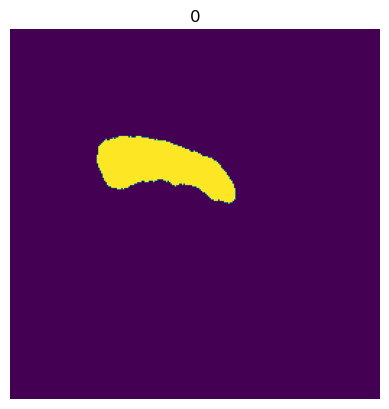

Interpolating image:   0%|          | 0/256 [00:00<?, ?it/s]

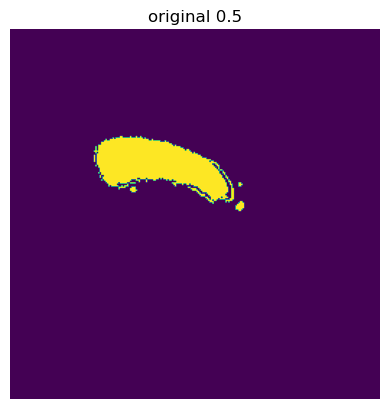

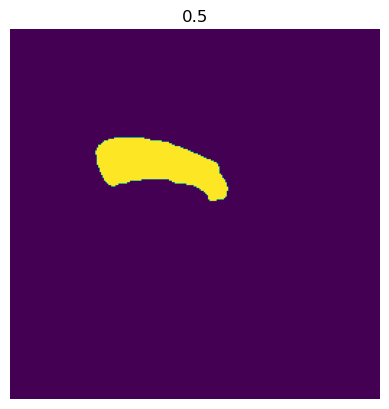

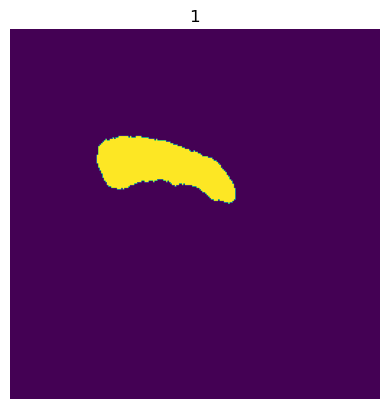

Label 850.0
DEBUG: Creating constraints.
(3455, 3)
DEBUG: Finished creating constraints.
Elapsed time: 1.780477523803711

DEBUG: Creating matrix.


Creating matrix:   0%|          | 0/3455 [00:00<?, ?it/s]

DEBUG: Finished constructing matrix
Elapsed time: 2.8383214473724365

DEBUG: Solving matrix.
DEBUG: Finished solving matrix.
Elapsed time: 0.3784191608428955
Elapsed time: 5.102410554885864


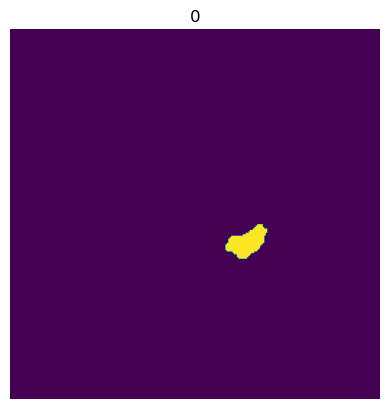

Interpolating image:   0%|          | 0/256 [00:00<?, ?it/s]

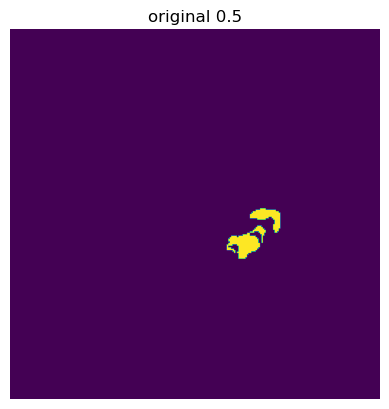

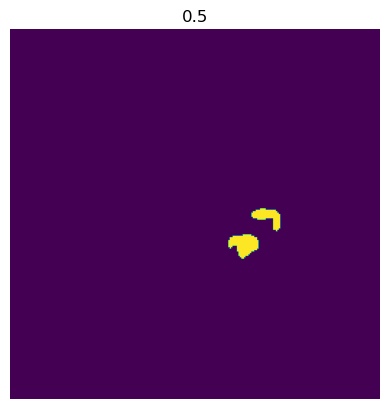

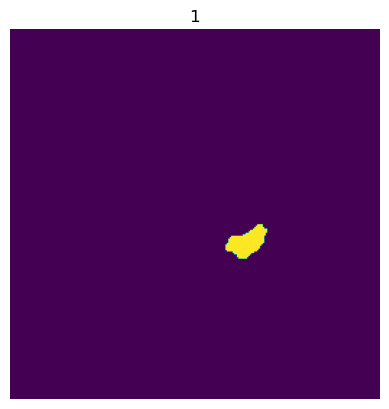

In [40]:
interp_output = {}
Mall = [Mall2, Mall2, Mall2, Mall1, Mall2]
Mall = np.array(Mall)

# MAKE SURE TO NORMALIZE TLIST
tlist = [0, 10, 30, 54, 60]
t = 35
tmax = 60

tlist = normalize_tlist(tlist, tmax)
t = get_idx(t, tmax)
print('t norm:', t)
print('tlist norm:', tlist)



for label in np.unique(Mall):
    if label != 0:
        print("Label", label)
        where_L = np.where(Mall != label)
        curr_M = Mall.copy()
        curr_M[where_L] = 0
        curr_M[curr_M == label] = 1

        # Create implicit surface
        start = time.time()
        imp = ImplicitFunction(curr_M, tmax=1, tlist=tlist)
        end = time.time() - start
        print(f"Elapsed time: {end}")

        # Interpolate image at some parametrization t
        #start = time.time()
        #img = imp.interpolate(0)
        plt.title("0"); plt.imshow(curr_M[0]); plt.axis(False); plt.show()
        
        #end = time.time() - start
        #print(f"Elapsed time: {end}")

        #print("0 with boundary constraints")
        #imp.data.show(0, img, [0])
        #print("0 with normal constraints")
        #imp.data.show(0, img, [1])
        #print("0 with outside constraints")
        #imp.data.show(0, img, [-1])

        #img = imp.interpolate(0.25)
        #plt.title("0.25"); plt.imshow(img); plt.axis(False); plt.show()

        img = imp.interpolate(t)
        plt.title("original 0.5"); plt.imshow(img); plt.axis(False); plt.show()
        img = skimage.morphology.remove_small_objects(img.astype(bool))
        img = skimage.morphology.remove_small_holes(img.astype(bool))
        img = median(img, disk(3))
        plt.title("0.5"); plt.imshow(img); plt.axis(False); plt.show()
        interp_output[label] = img
        
        plt.title("1"); plt.imshow(curr_M[1]); plt.axis(False); plt.show()
        
        #if label == 500:
        #    break

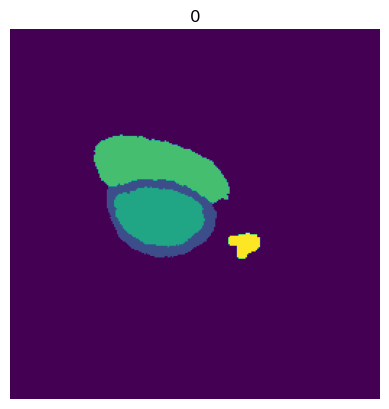

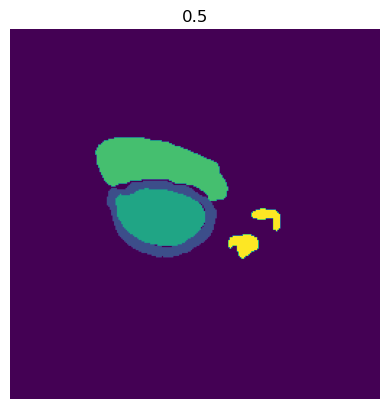

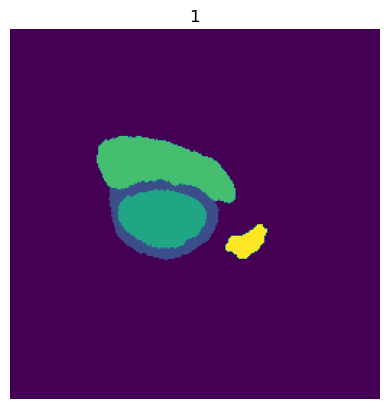

In [41]:
# Combine all labels into one image
canvas = np.zeros(Mall1.shape)
for key in interp_output.keys():
    curr_label = interp_output[key]
    where_label = np.where(curr_label != 0)
    canvas[where_label] = key
    

plt.title('0')
plt.axis(False)
plt.imshow(Mall1)
plt.show()
    
plt.title('0.5')
plt.axis(False)
plt.imshow(canvas)
plt.show()


plt.title('1')
plt.axis(False)
plt.imshow(Mall2)
plt.show()

min -168.70562744140625
max 14.29705810546875


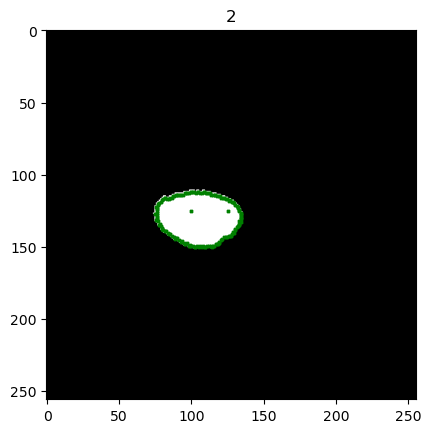

In [39]:
constraints = imp.data.constraints[2]
#for c in constraints:
#    print(c[1])
h = imp.data.get_h()
print('min', np.min(h))
print('max', np.max(h))

imp.data.show(2, target=[1])

Test gridding

In [76]:
s = None
s2 = 0

s2 is not None

True

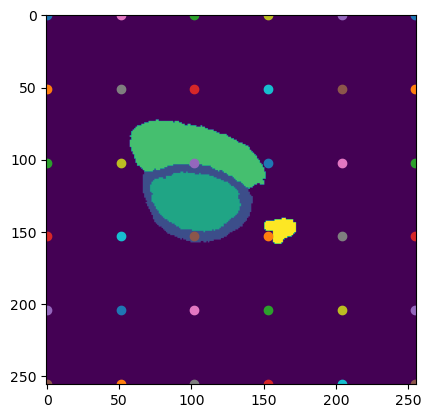

In [74]:
spacing = 0.2

w = Mall1.shape[-1]
h = Mall1.shape[-2]
wspacing = w * spacing
hspacing = h * spacing

plt.imshow(Mall1)

for x in range(0, w, int(w * spacing)):
    for y in range(0, h, int(h * spacing)):
        plt.plot(x, y, marker='o')

plt.show()

# Try 3D to 3D
Ma = volume[0, :]
Mb = volume[15, :]
Mab = np.array([Ma, Mb])
np.save('M0.npy', Ma)
np.save('M15.npy', Mb)
print(Mab.shape)

"""
for i in range(Ma.shape[0]):
    fig, ax = plt.subplots(1, 2)
    ax[0].imshow(Ma[i])
    ax[1].imshow(Mb[i])
    plt.show()
""" 
imp = ImplicitFunction(Mab, tmax=1)
img = imp.interpolate(0.5)

(10, 216, 256)


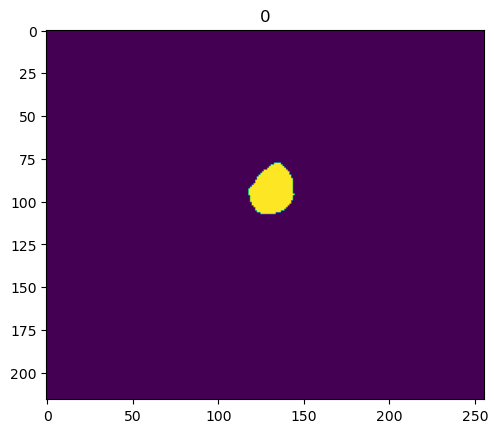

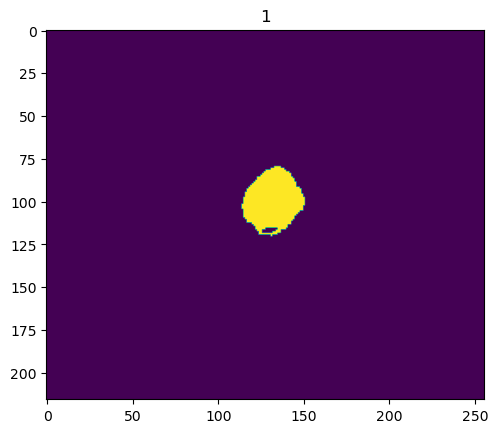

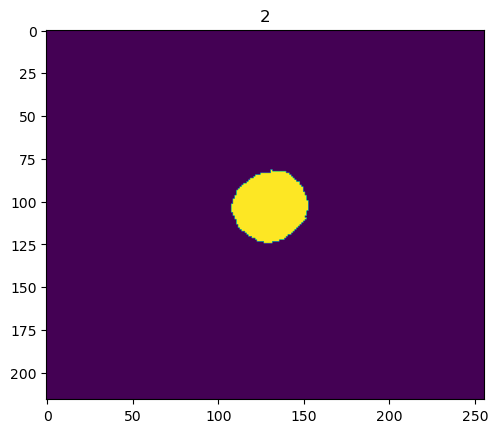

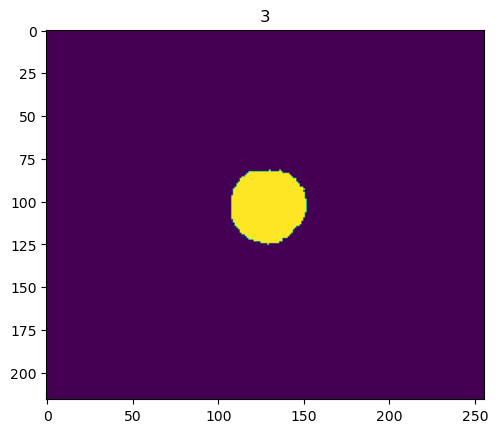

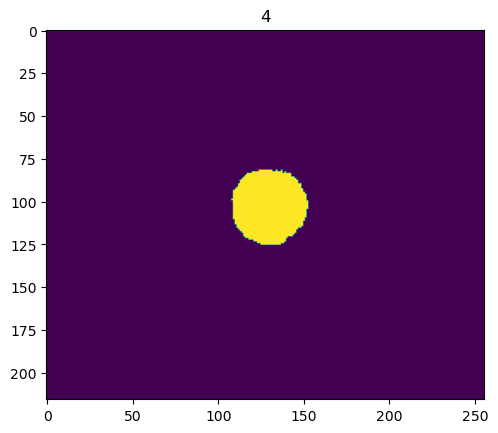

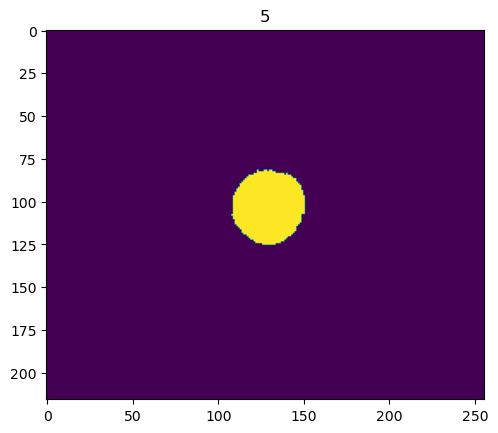

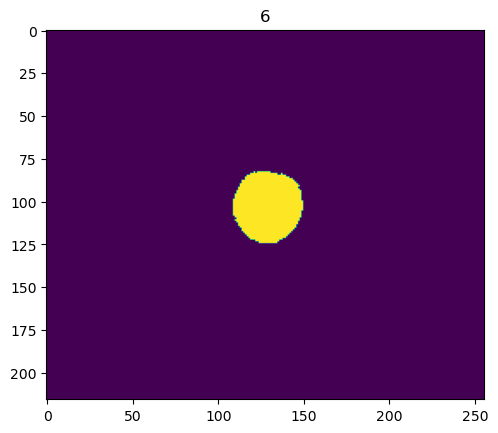

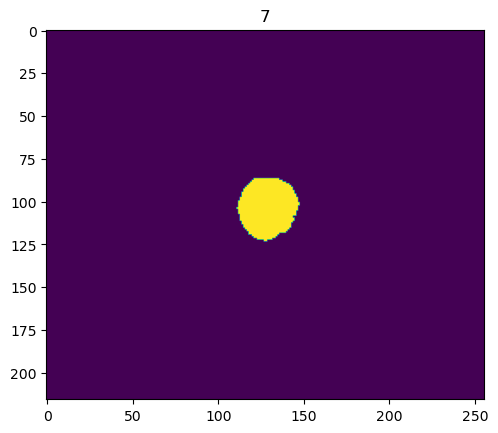

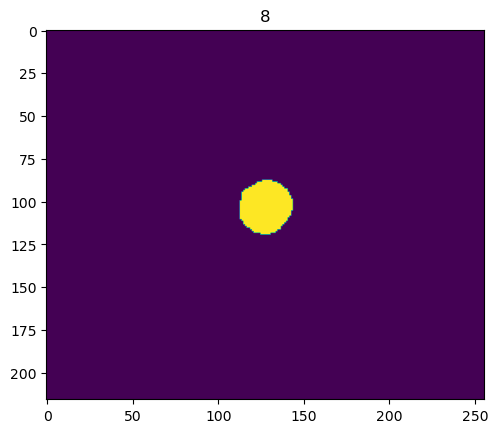

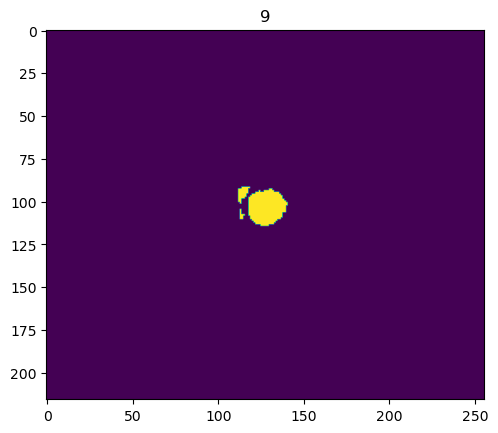

In [38]:
print(img.shape)

for i in range(img.shape[0]):
    plt.imshow(img[i])
    plt.title(str(i))
    plt.show()

np.save('interpolated3dlv2.npy', img)

## 12-15-23 end

DEBUG: Creating constraints.
DEBUG: Finished creating constraints.
Elapsed time: 16.251675128936768

DEBUG: Creating matrix.


Creating matrix:   0%|          | 0/9428 [00:00<?, ?it/s]

DEBUG: Finished constructing matrix
Elapsed time: 22.801040410995483

DEBUG: Solving matrix.
DEBUG: Finished solving matrix.
Elapsed time: 2.1656744480133057
Elapsed time: 49.34825253486633


Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

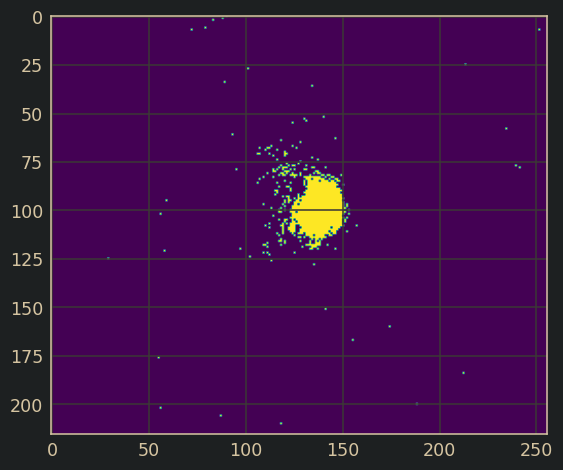

Elapsed time: 135.94837260246277


Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

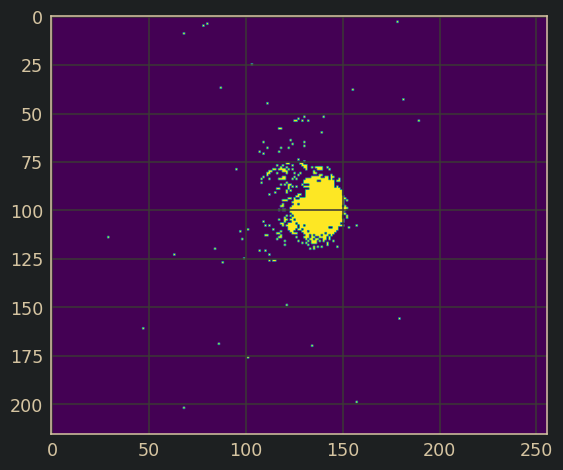

Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

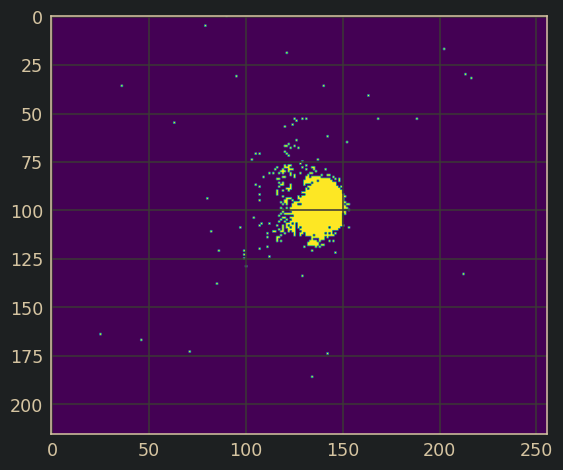

Interpolating image:   0%|          | 0/216 [00:00<?, ?it/s]

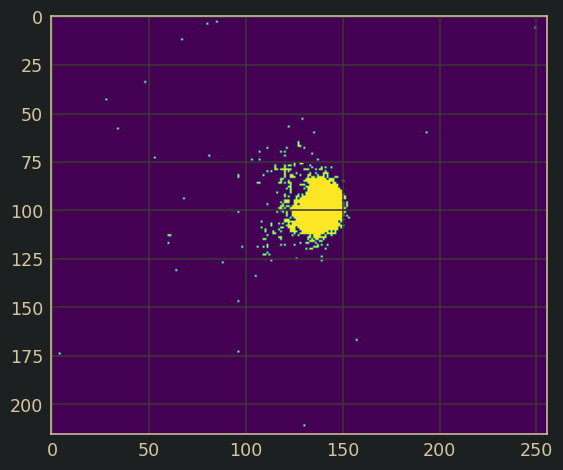

In [7]:
# Create implicit surface
start = time.time()
imp = ImplicitFunction(M, tmax=1)
end = time.time() - start
print(f"Elapsed time: {end}")

# Interpolate 2D image at some parametrization t
start = time.time()
img = imp.interpolate(0)
plt.imshow(img); plt.show()
end = time.time() - start
print(f"Elapsed time: {end}")


img = imp.interpolate(0.25)
plt.imshow(img); plt.show()

img = imp.interpolate(0.75)
plt.imshow(img); plt.show()

img = imp.interpolate(1.0)
plt.imshow(img); plt.show()

### Show original input volume slices

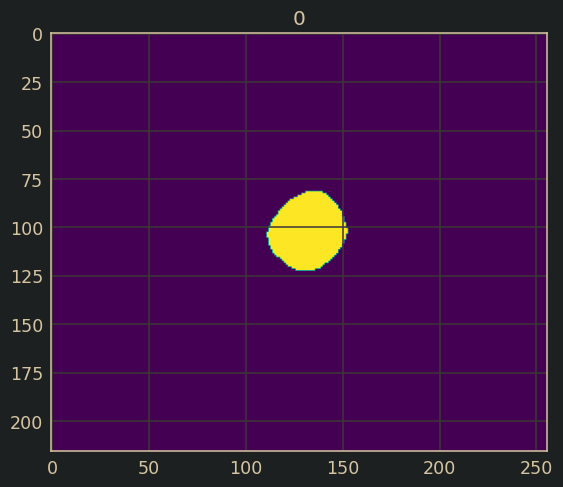

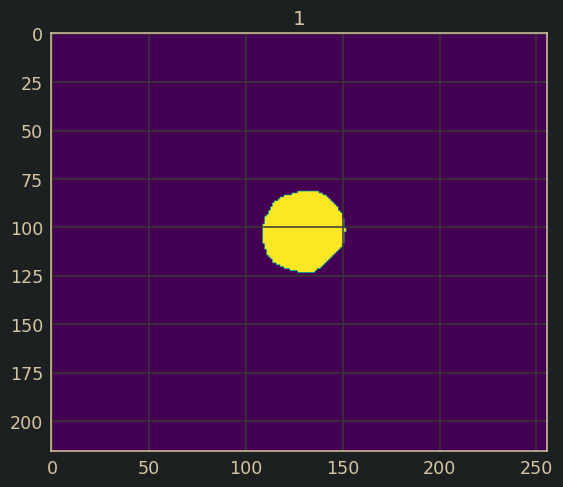

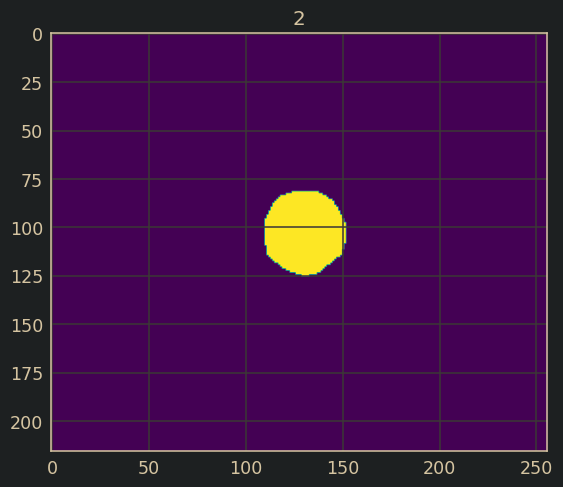

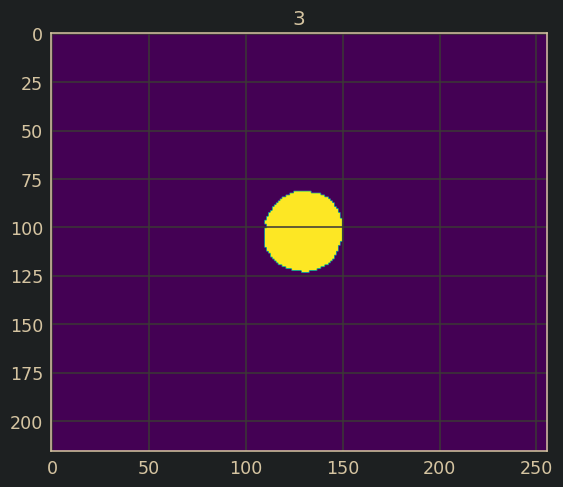

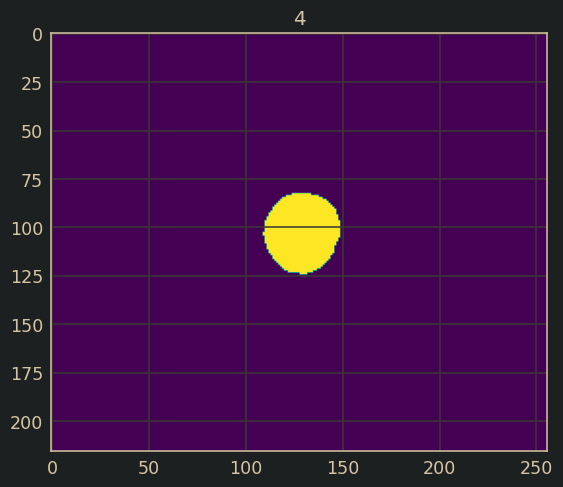

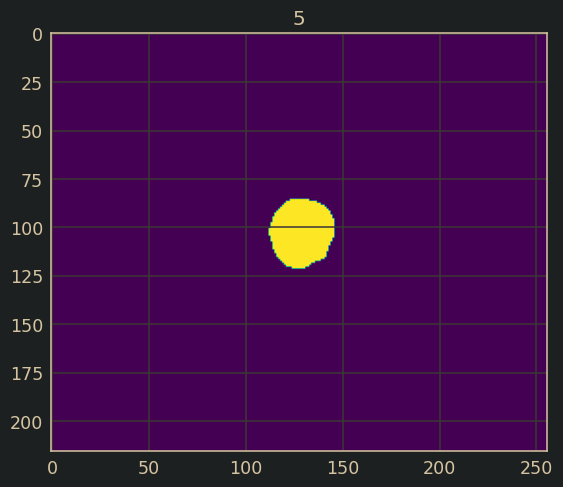

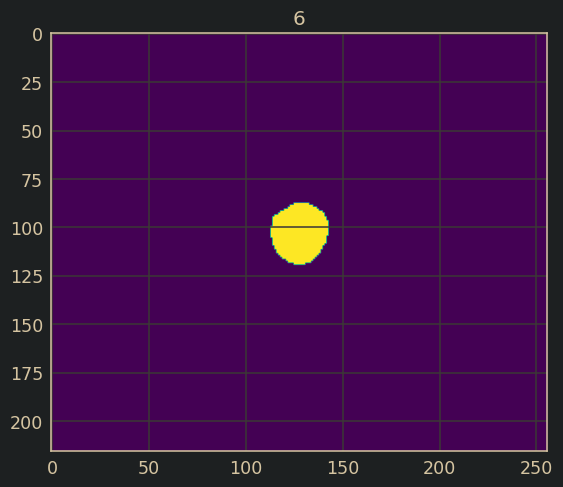

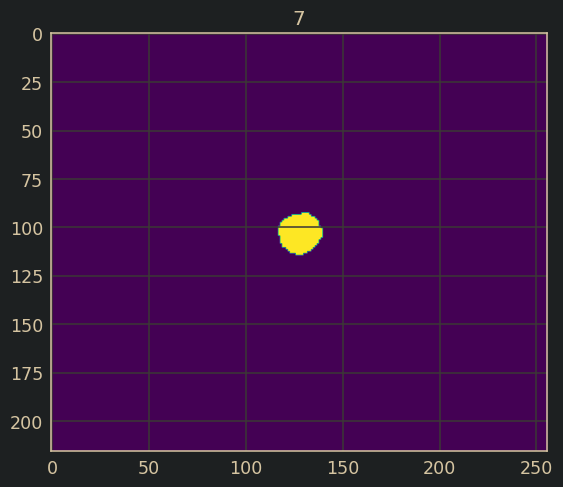

In [8]:
# Show slices for original volume 0
for idx in range(M.shape[0]):
    plt.imshow(M[idx])
    plt.title(idx)
    plt.show()

### Interpolate results for 3D input

# Show slices for generated volume
for idx in range(vol.shape[0]):
    plt.imshow(vol[idx])
    plt.title(f"Index {idx}")
    plt.show()

## Show result in PyVista